## Imports

In [ ]:
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector, Operator
from qiskit.primitives import StatevectorSampler
from qiskit.visualization import plot_histogram
from qiskit.visualization import plot_bloch_vector
from qiskit.primitives import StatevectorSampler
from qiskit.visualization import plot_histogram

from math import sqrt, pi
import random

## 2-qubits Grover

In [172]:
def make_oracle_circuit(target):
  oracle_circuit = QuantumCircuit(2, 2)

  if target == "00":
    oracle_circuit.x(0)
    oracle_circuit.x(1)
    oracle_circuit.cz(0, 1)
    oracle_circuit.x(0)
    oracle_circuit.x(1)
  if target == "01":
    oracle_circuit.x(0)
    oracle_circuit.cz(0, 1)
    oracle_circuit.x(0)
  if target == "10":
    oracle_circuit.x(1)
    oracle_circuit.cz(0, 1)
    oracle_circuit.x(1)
  if target == "11":
    oracle_circuit.cz(0, 1)

  return oracle_circuit

In [173]:
def make_diffuser_circuit():
  diffuser_circuit = QuantumCircuit(2, 2)
  diffuser_circuit.h(0)
  diffuser_circuit.h(1)
  diffuser_circuit.x(0)
  diffuser_circuit.x(1)

  diffuser_circuit.cz(0, 1)

  diffuser_circuit.x(0)
  diffuser_circuit.x(1)
  diffuser_circuit.h(0)
  diffuser_circuit.h(1)

  return diffuser_circuit

In [174]:
def grover2(target):
  grover_circuit = QuantumCircuit(2, 2)
  grover_circuit.h(0)
  grover_circuit.h(1)
  grover_circuit.barrier()

  oracle_circuit = make_oracle_circuit(target)
  diffuser_circuit = make_diffuser_circuit()

  grover_circuit = grover_circuit.compose(oracle_circuit)
  grover_circuit.barrier()
  grover_circuit = grover_circuit.compose(diffuser_circuit)
  grover_circuit.compose(diffuser_circuit)

  grover_circuit.barrier()

  grover_circuit.measure([0, 1], [1, 0])

  grover_circuit.draw()

  return grover_circuit

In [175]:
grover2_circuit = grover2("00")
print(grover2_circuit)

job = StatevectorSampler().run([grover2_circuit], shots=1024)
result = job.result()

data = result[0].data
counts = data.c.get_counts()

print(counts)

     ┌───┐ ░ ┌───┐   ┌───┐ ░ ┌───┐┌───┐   ┌───┐┌───┐ ░ ┌─┐   
q_0: ┤ H ├─░─┤ X ├─■─┤ X ├─░─┤ H ├┤ X ├─■─┤ X ├┤ H ├─░─┤M├───
     ├───┤ ░ ├───┤ │ ├───┤ ░ ├───┤├───┤ │ ├───┤├───┤ ░ └╥┘┌─┐
q_1: ┤ H ├─░─┤ X ├─■─┤ X ├─░─┤ H ├┤ X ├─■─┤ X ├┤ H ├─░──╫─┤M├
     └───┘ ░ └───┘   └───┘ ░ └───┘└───┘   └───┘└───┘ ░  ║ └╥┘
c: 2/═══════════════════════════════════════════════════╩══╩═
                                                        1  0 
{'00': 1024}


## 3-qubits Grover

In [176]:
# Target = 101
def make_oracle_circuit3():
  oracle_circuit = QuantumCircuit(3, 3)
  oracle_circuit.x(1)
  oracle_circuit.ccz(0, 2, 1)
  oracle_circuit.x(1)

  return oracle_circuit

In [177]:
def make_diffuser_circuit3():
  diffuser_circuit = QuantumCircuit(3, 3)
  diffuser_circuit.h([0, 1, 2])
  diffuser_circuit.x([0, 1, 2])

  diffuser_circuit.ccz(0, 1, 2)

  diffuser_circuit.x([0, 1, 2])
  diffuser_circuit.h([0, 1, 2])

  return diffuser_circuit

In [178]:
oracle_circuit = make_oracle_circuit3()
oracle_circuit.draw()

q_0: ──────■──────
     ┌───┐ │ ┌───┐
q_1: ┤ X ├─■─┤ X ├
     └───┘ │ └───┘
q_2: ──────■──────
                  
c: 3/═════════════

In [179]:
diffuser_circuit = make_diffuser_circuit3()
diffuser_circuit.draw()

┌───┐┌───┐   ┌───┐┌───┐
q_0: ┤ H ├┤ X ├─■─┤ X ├┤ H ├
     ├───┤├───┤ │ ├───┤├───┤
q_1: ┤ H ├┤ X ├─■─┤ X ├┤ H ├
     ├───┤├───┤ │ ├───┤├───┤
q_2: ┤ H ├┤ X ├─■─┤ X ├┤ H ├
     └───┘└───┘   └───┘└───┘
c: 3/═══════════════════════

In [180]:
def oracle_and_diffuser_circuit():
  oracle_circuit = make_oracle_circuit3()
  diffuser_circuit = make_diffuser_circuit3()

  circuit = QuantumCircuit(3, 3)
  circuit = circuit.compose(oracle_circuit)
  circuit.barrier()
  circuit = circuit.compose(diffuser_circuit)
  circuit.barrier()

  return circuit

In [181]:
def grover3(r=1):
  grover_circuit = QuantumCircuit(3, 3)
  oracle_circuit = make_oracle_circuit3()
  diffuser_circuit = make_diffuser_circuit3()

  grover_circuit.h([0, 1, 2])

  for i in range(r):
    grover_circuit = grover_circuit.compose(oracle_and_diffuser_circuit())

  grover_circuit.measure([0, 1, 2], [2, 1, 0])

  return grover_circuit

{'101': 973, '010': 7, '110': 10, '000': 5, '100': 8, '001': 6, '111': 10, '011': 5}


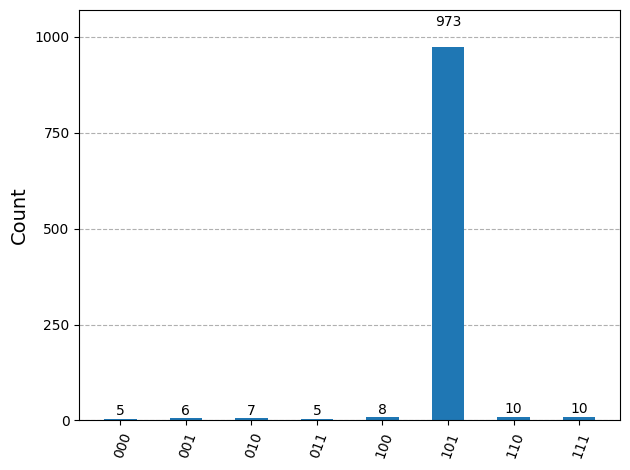

In [182]:
grover3_circuit = grover3(2)

job = StatevectorSampler().run([grover3_circuit], shots=1024)
result = job.result()
data = result[0].data
counts = data.c.get_counts()

print(counts)
plot_histogram(counts)

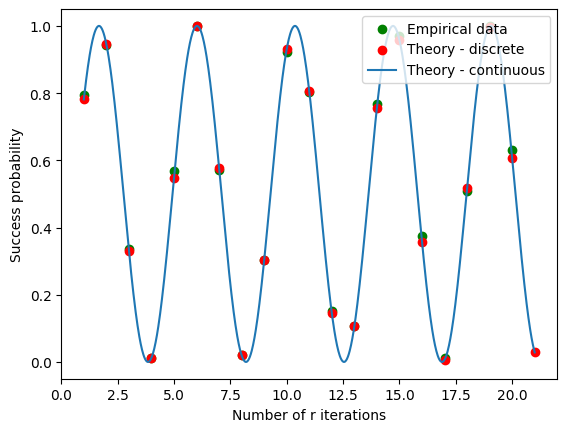

In [183]:
import numpy as np
import matplotlib.pyplot as plt

probs_distr = []
for r in range(1,21):
  grover3_circuit = grover3(r)

  job = StatevectorSampler().run([grover3_circuit], shots=1024)
  result = job.result()
  data = result[0].data
  counts = data.c.get_counts()

  probs_distr.append(counts['101'] / 1024)

# Empirical data
plt.scatter(range(1, 21), probs_distr, c="green", label="Empirical data")

# Theoretical scattering
theta = 2 * np.arcsin(1 / np.sqrt(8))
theorerical_points = []
for r in range(1, 21):
  theorerical_points.append(np.sin((r + 1/2) * theta)**2)

plt.scatter(np.linspace(1, 21, 21), np.sin((np.linspace(1, 21, 21) + 1/2)*theta)**2, c="red", label="Theory - discrete")

# Theoretical (continuous)
plt.plot(np.linspace(1, 21, 1000), np.sin((np.linspace(1, 21, 1000) + 1/2)*theta)**2, label="Theory - continuous")
plt.legend(loc='upper right')
plt.xlabel("Number of r iterations")
plt.ylabel("Success probability")
plt.show()


On remarque que le 1er pic empirique se trouve à r = 2. Ce qui est cohérent avec la théorie où r ~ round(π/4 sqrt(N)) = 2 pour N = 2^3 = 8